# Stat 220, Unit 8 Homework: Probability as a Model

Much of this is pencil work. For parts marked **by hand**, work out the calculation
before using the code cell to check it. Please enter the formula you used rather than typing
the answer directly. For example, enter the multiplication that gives the answer and let
Python calculate the result.

The first five problems use small examples or model information given in the question.
The last two use the 700 lawn mowing jobs from Unit 5 and the 500 delivery routes from the
Unit 4 and Unit 6 homeworks. You will estimate probabilities from those data and compare
them with what a fitted model predicts.

Run the next two cells first.

In [1]:
%pip install -q numpy pandas scipy matplotlib

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import binom, poisson, expon, norm, lognorm

lawn = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/lawn_jobs.csv")
routes = pd.read_csv("https://drbob-richardson.github.io/stat220/F2026/data/delivery_routes.csv")
lawn.head()

,minutes,lot_sqft,slope,obstacles,gated,crew_size,invoice_id,customer_rating
0,13.3,11125,flat,3,0,3,50761,5
1,4.5,1362,moderate,4,0,3,68868,4
2,14.4,5919,flat,3,0,1,89918,2
3,32.8,15539,flat,3,1,1,64082,4
4,6.8,3532,flat,3,0,3,82748,3


For a discrete distribution, `pmf(k, ...)` gives the probability of exactly `k`, and `sf(k, ...)` gives the probability of more than `k`. For a continuous distribution, `cdf(x, ...)` gives the area below `x`, `sf(x, ...)` gives the area above it, and `ppf(q, ...)` gives the value with proportion `q` below it.

**Problem 1.** Of the 700 lawn mowing jobs, 144 were at properties with a gate.
Let $p$ be the probability that a job is at a gated property. For now, assume that new
bookings are independent and have the same gate probability as these jobs.

Part a. **By hand.** Estimate $p$ using the counts above. Write the fraction and
calculate its value. Then check it using the `gated` column in `lawn`, where 1 means the
property has a gate and 0 means it does not.

In [5]:
144/700

0.2057142857142857

In [6]:
lawn.gated.mean()

np.float64(0.2057142857142857)

Part b. **By hand.** Twenty-five jobs are booked for next week. Using your estimate
from part a, give the mean and standard deviation of the number of gated jobs. Show the
variance calculation before taking the square root.

In [7]:
n = 25
p = 144/700

mean = n * p
var = n * p * (1 - p)
sd = np.sqrt(var)

mean, var, sd

(5.142857142857142, 4.084897959183673, np.float64(2.0211130495802734))

Part c. Use `binom` to find the probability that exactly 5 of the 25 jobs are gated,
then the probability that 8 or more are gated. Which probability would be more useful if
the company needed extra equipment whenever it had at least 8 gated jobs?

In [9]:
p_of_5 = binom.pmf(5, 25, p)
p_8_plus = binom.sf(7, 25, p)   # P(X > 7) = P(X ≥ 8)

p_of_5, p_8_plus

(np.float64(0.19552266480920347), np.float64(0.12393234209954235))

_Your answer:_ If the company needed extra equipment wheneber it had at least 8 gated jobs, then the probability of 8 or more would be much more useful (pr = ~12% or 0.124)



**Problem 2.** A smaller example will help us see how likelihood works. The office sends
10 quotes, and 3 become bookings. Assume independent responses with a common booking
probability $p$. We will use the likelihood of the individual responses.

Part a. **By hand.** Write the likelihood $\mathcal L(p)$ for these responses.
Fill in the exponents in $p^{\square}(1-p)^{\square}$ and explain what each exponent counts.

_Your answer:_ L(p) = p^3(1-p)^7. The exponent of 3 is the number of quotes that turn into bookings, and the exponent of 7 is the number of quotes that didn't turn into bookngs.



Part b. **By hand.** Evaluate the likelihood at $p=0.20$, $p=0.30$, and $p=0.50$.
Show the powers and multiplication in your code cell. Which of these values gives the
largest likelihood? How does it compare with the observed booking proportion?

In [11]:
L_20 = 0.20**3 * 0.80**7
L_30 = 0.30**3 * 0.70**7
L_50 = 0.50**3 * 0.50**7

L_20, L_30, L_50

(0.001677721600000001, 0.002223566099999999, 0.0009765625)

_Your answer:_ The value that gives the largest likelinhood is where p = 0.30 which produces a result of about 0.002. This is exactly the same as teh obeserved booking proportion of 3/10 (0.3).



Part c. Now calculate $\log\mathcal L(p)$ for the same three values, using
$3\log(p)+7\log(1-p)$. Does taking the log change which value fits best? In two sentences,
explain why software uses log-likelihood and why the highest likelihood does not mean
there is a high probability that $p$ equals that value.

In [12]:
logL_20 = 3*np.log(0.20) + 7*np.log(0.80)
logL_30 = 3*np.log(0.30) + 7*np.log(0.70)
logL_50 = 3*np.log(0.50) + 7*np.log(0.50)

logL_20, logL_30, logL_50

(np.float64(-6.390318596501769),
 np.float64(-6.108643020548936),
 np.float64(-6.931471805599452))

_Your answer:_ Taking the log does not change which value fits best since -6.1 is the highest number among the logged values. Softare uses the log because it is easier to work with larger numbers than with the small numbers that we see without using logs. The highest likelihood does not mean that there is a high probability that p is equal to that value, but rather it is the value that makes the 3/10 probability most likely occur.



**Problem 3.** The lawn company's office receives cancellation calls at an average rate
of 2 per hour. Suppose the calls follow a Poisson process with a constant rate. The count
over a time period is Poisson, and the waiting time between calls is exponential.

Part a. **By hand.** Give the mean, variance, and standard deviation of the number
of calls in one hour. Then do the same for a three-hour period. Keep track of the time
period that goes with each Poisson parameter.

In [13]:
lam_1 = 2        # 1 hour
lam_3 = 2 * 3    # 3 hours

mean_1, var_1, sd_1 = lam_1, lam_1, np.sqrt(lam_1)
mean_3, var_3, sd_3 = lam_3, lam_3, np.sqrt(lam_3)

(mean_1, var_1, sd_1), (mean_3, var_3, sd_3)

((2, 2, np.float64(1.4142135623730951)), (6, 6, np.float64(2.449489742783178)))

Part b. **By hand.** Find the probability of no calls in the next hour using
$\mathbb P(X=0)=e^{-\lambda}$. Check it with `poisson.pmf`. Then use `poisson.sf` to find
the probability of 4 or more calls in that hour.

In [15]:
lam = 2
# e^(-2)
np.exp(-lam)


np.float64(0.1353352832366127)

In [16]:
p0_check = poisson.pmf(0, lam)

p_4_or_more = poisson.sf(3, lam)   # P(X > 3) = P(X ≥ 4)

p0_check, p_4_or_more

(np.float64(0.1353352832366127), np.float64(0.14287653950145296))

Part c. **By hand.** What is the mean wait between calls, in minutes? Use
$\mathbb P(T>t)=e^{-t/30}$ to find the chance of waiting more than 15 minutes and more
than 30 minutes. Check your answers with `expon.sf(t, scale=30)`. Why is the probability
of waiting longer than the mean not 0.50?

In [17]:
mean_wait = 60 / 2   # minutes

p15_hand = np.exp(-15/30)
p30_hand = np.exp(-30/30)

p15_check = expon.sf(15, scale=30)
p30_check = expon.sf(30, scale=30)

mean_wait, p15_hand, p15_check, p30_hand, p30_check

(30.0,
 np.float64(0.6065306597126334),
 np.float64(0.6065306597126334),
 np.float64(0.36787944117144233),
 np.float64(0.36787944117144233))

_Your answer:_ The probability of waiting is longer than the meean is not 0.50 because the distribution is probably not perfectly symmmetrical. The data appears to be skewed down since the probability of waiting more than the mean at 30 is only ~ 0.37.



Part d. No calls have arrived for 30 minutes. Under this model, what is the chance
of waiting at least another 15 minutes? Explain which property of the exponential
distribution you used. Would a higher cancellation rate on rainy mornings make one
constant rate a reasonable model for all mornings?

In [18]:
# P(T > 45 | T > 30) = P(T > 45) / P(T > 30)
p_cond = expon.sf(45, scale=30) / expon.sf(30, scale=30)
p_fresh = expon.sf(15, scale=30)

p_cond, p_fresh

(np.float64(0.6065306597126334), np.float64(0.6065306597126334))

_Your answer:_ The property of exponential distribution I used is memoryless. This model fits a poisson process where what comes next doesn't depend on what came before. A constant rate would not be reasonable for all mornings if there is a higher cancellation rate on rainy mornings. A better model would separate them by the weather so you can predict accurately for both rainy and dry mornings.



**Problem 4.** For one delivery route, a model predicts 55 minutes and gives a 95%
prediction interval of 40 to 70 minutes. Treat the forecast as normal and use 1.96 as the
critical value. We will use this forecast to make a delivery promise.

Part a. **By hand.** Recover $\mathrm{SE}_{\mathrm{pred}}$ from the interval.
Show the width divided by $2\times1.96$. Store the result as `se_pred` for the next parts.

In [19]:
se_pred = (70 - 40) / (2 * 1.96)
se_pred

7.653061224489796

Part b. **By hand.** Find the z-score for 60 minutes. Then use `norm.sf` to find
the chance of missing a 60-minute delivery promise, and `norm.cdf` to find the chance
of finishing between 45 and 65 minutes.

In [20]:
z_60 = (60 - 55) / se_pred

p_miss_60 = norm.sf(60, loc=55, scale=se_pred)

p_45_to_65 = norm.cdf(65, loc=55, scale=se_pred) - norm.cdf(45, loc=55, scale=se_pred)

z_60, p_miss_60, p_45_to_65

(0.6533333333333333,
 np.float64(0.2567707037112674),
 np.float64(0.808674055819318))

Part c. What delivery time would allow 90% of similar routes to finish by the
promised time? Use `norm.ppf`. Explain why the point prediction of 55 minutes does not
provide the same level of coverage.

In [21]:
promise_90 = norm.ppf(0.90, loc=55, scale=se_pred)
promise_90

np.float64(64.80779259345357)

_Your answer:_ 55 minutes doesn't give the same level of coverage because it is the center of the spread. That means that under normal circumstances that half of the routes would be above 55.



Part d. **By hand.** Suppose three independent routes have this same forecast.
Give the mean and standard deviation of their total time, showing the variance step.
Then use the normal distribution to find the chance that the total exceeds 180 minutes.
Name one reason route times might not be independent in practice.

In [22]:
mean_total = 3 * 55

# se_pred^2 + se_pred^2 + se_pred^2
var_total = 3 * se_pred**2
sd_total = np.sqrt(var_total)

p_over_180 = norm.sf(180, loc=mean_total, scale=sd_total)

mean_total, var_total, sd_total, p_over_180

(165,
 175.70803831736777,
 np.float64(13.255490874251612),
 np.float64(0.12889994727049414))

_Your answer:_ In practice, route times might not be independent because all three routes share similar conditions, bad weather or road closure could change things in a way that is not represented in these three routes.



**Problem 6.** Now use the data to check some Poisson models. `lawn.obstacles` counts
trees, garden beds, and other obstacles at each property. In `routes`, `packages` counts
parcels on a route and `van_age_years` records the van's age in whole years.
Use the sample variance, as returned by `.var()`.

Part a. For `obstacles`, estimate $\lambda$ with the sample mean. Calculate the
sample variance and the variance-to-mean ratio. What relationship would you expect under
a Poisson model, and how close are these data to it?

In [23]:
lam_obs = lawn.obstacles.mean()
var_obs = lawn.obstacles.var()
ratio_obs = var_obs / lam_obs

lam_obs, var_obs, ratio_obs

(np.float64(3.045714285714286),
 3.2511260985080708,
 np.float64(1.0674429028872652))

_Your answer:_ Under a Poisson model I would expect the variance to be similar to the mean with a ratio roughly equal to 1. That is the case with this data as the mean (3.046) is close to the variance (3.251) and the ratio is roughly equal to 1 (1.067).



Part b. Using your fitted Poisson model, find the probability of no obstacles and
of 6 or more obstacles. Put each beside its observed proportion in the data. For example,
`(lawn.obstacles == 0).mean()` gives the observed proportion with no obstacles.
Do these comparisons support using a Poisson model? Explain briefly.

In [24]:
p0_model = poisson.pmf(0, lam_obs)
p0_data = (lawn.obstacles == 0).mean()

p6_model = poisson.sf(5, lam_obs)
p6_data = (lawn.obstacles >= 6).mean()

(p0_model, p0_data), (p6_model, p6_data)

((np.float64(0.047562326760850836), np.float64(0.05285714285714286)),
 (np.float64(0.08859684585054182), np.float64(0.09571428571428571)))

_Your answer:_ These comparisons seem to support using a Poisson model. In both cases, the model predicts slightly lower than what the data supports, but the numbers are close and the model is consistent in offering a lower prediction (theres not one that predicts higher while the other predicts lower). The fitted Poisson gives Pr(0 obstacles) = ~ 0.048 with data supporting ~ 0.053, and Pr(6 or more obstacles) = ~ 0.089 with data supporting ~ 0.096. That's less than 1% difference in both cases.



Part c. For `routes.packages`, calculate the mean, variance, and variance-to-mean
ratio. Compare the fitted Poisson probability of more than 200 parcels with the observed
proportion. What is overdispersion, and what could a dispatcher underestimate by using
this Poisson model?

In [25]:
lam_pk = routes.packages.mean()
var_pk = routes.packages.var()
ratio_pk = var_pk / lam_pk

p200_model = poisson.sf(200, lam_pk)
p200_data = (routes.packages > 200).mean()

lam_pk, var_pk, ratio_pk, p200_model, p200_data

(np.float64(105.508),
 2962.418773547091,
 np.float64(28.07766968900075),
 np.float64(9.486929516696062e-17),
 np.float64(0.044))

_Your answer:_ Overdispersion is when the data shows more variation than the model allows. In Poisson the variance should equal the mean, but in this case the variance is several times the mean. Using a Poisson model for routes could cause a dispatcher to underestimate the chance of having an abnormally busy route. Routes with 200+ packages do happen and a dispatcher might not plan accordingly.



Part d. For `routes.van_age_years`, calculate the mean, variance, and their ratio.
Then compare the observed numbers of vans aged 0 and 8 with the expected numbers under
the fitted Poisson model. An expected number is `len(routes) * poisson.pmf(k, lam)`.
Is a variance-to-mean ratio near 1 enough to conclude that the model fits? Use your
results to explain.

In [26]:
lam_van = routes.van_age_years.mean()
var_van = routes.van_age_years.var()
ratio_van = var_van / lam_van

obs_0 = (routes.van_age_years == 0).sum()
exp_0 = len(routes) * poisson.pmf(0, lam_van)

obs_8 = (routes.van_age_years == 8).sum()
exp_8 = len(routes) * poisson.pmf(8, lam_van)

lam_van, var_van, ratio_van, (obs_0, exp_0), (obs_8, exp_8)

(np.float64(4.524),
 5.259943887775546,
 np.float64(1.16267548359318),
 (np.int64(0), np.float64(5.422777285018024)),
 (np.int64(65), np.float64(23.59837046862277)))

_Your answer:_ The ratio of variance to mean is ~ 1.16 which is close to one, but the observed at age 0 (0) is 5.42 values less than what is expected at age 0. Interestingly, the observed at age 8 (65) is much higher than the expected value (23.598). It is important to conduct more analysis than simply looking at the variance/mean ratio because even if it is close to one, the actual distribution could still be misshapen.



**Problem 7.** Finally, compare normal and lognormal models for `lawn.minutes`.
We are modeling the times across all properties in the dataset, rather than making
a forecast for one particular property.

Part a. Calculate the mean, standard deviation, and skewness of `minutes`.
Fit a normal model using the mean and SD, and compare its probability of a job taking
more than 30 minutes with the observed proportion. How close are the two probabilities?

In [27]:
mean_min = lawn.minutes.mean()
sd_min = lawn.minutes.std()
skew_min = lawn.minutes.skew()

p30_normal = norm.sf(30, loc=mean_min, scale=sd_min)
p30_data = (lawn.minutes > 30).mean()

mean_min, sd_min, skew_min, p30_normal, p30_data

(np.float64(15.32342857142857),
 6.690216178863461,
 np.float64(1.9390597064611426),
 np.float64(0.01412717908280276),
 np.float64(0.03428571428571429))

_Your answer:_ The probability of a job taking more than 30 minutes in our data (0.034) is 2% higher than what a normal distribution would expect (0.014). This implies a right skew on the data which would increase the chances of having higher values.



Part b. What probability does the same normal model assign to a job taking less
than zero minutes? Why is that a concern here? Discuss it alongside the comparison in
part a when deciding whether this model is useful for scheduling.

In [28]:
p_negative = norm.cdf(0, loc=mean_min, scale=sd_min)
p_negative

np.float64(0.010998388339553078)

_Your answer:_ The normal model assigns a probability of ~ 0.011 to a job taking less than 0 minutes. This is obviously a concern because it is impossible for a job to take a negative amount of time, so the model should probably have a lower bound placed at zero. This makes sense because part a helps us to recognize the skewness of the data.

Part c. Run these Q-Q plots, which compare `minutes` and `log(minutes)` with a
normal distribution. Describe the main pattern in each plot. Which scale looks closer
to normal?

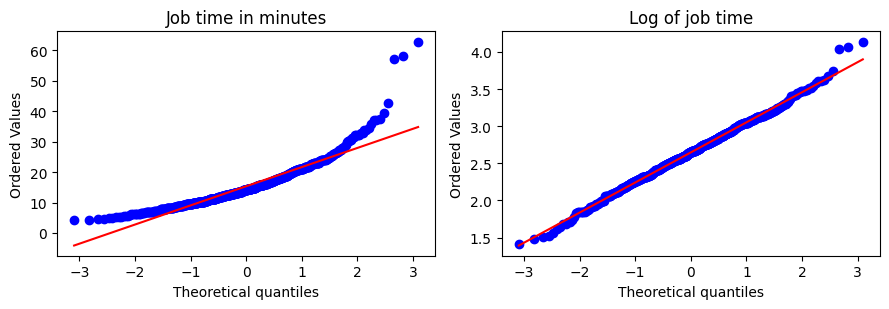

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
stats.probplot(lawn.minutes, dist="norm", plot=axes[0])
axes[0].set_title("Job time in minutes")
stats.probplot(np.log(lawn.minutes), dist="norm", plot=axes[1])
axes[1].set_title("Log of job time")
plt.tight_layout()
plt.show()

_Your answer:_

1.   Looking at Job time in minutes, we can see a clearly parabolic shape in the data, causing us to doubt its normality.
2.   However under a log of job time, values very closely follow the QQ plot line which supports a closer fit of the data and stronger normality.





Part d. Calculate the mean and SD of `np.log(lawn.minutes)`. Use them as `mu_log`
and `sigma_log` in a lognormal model, then find its probability of a job taking more
than 30 minutes using `lognorm.sf(30, s=sigma_log, scale=np.exp(mu_log))`.
Compare this with part a and the observed proportion. Which model would you recommend
for estimating this probability, and what evidence supports your choice?

In [30]:
log_min = np.log(lawn.minutes)
mu_log = log_min.mean()
sigma_log = log_min.std()

p30_lognorm = lognorm.sf(30, s=sigma_log, scale=np.exp(mu_log))

mu_log, sigma_log, p30_lognorm, p30_normal, p30_data

(np.float64(2.6466962314963633),
 0.4046322713331059,
 np.float64(0.0311146183330778),
 np.float64(0.01412717908280276),
 np.float64(0.03428571428571429))

_Your answer:_ Looking at the probabilities using lognormal versus normal and the observed data, the lognormal value (0.031) appear to be much closer to our data (0.034) than the expected normal (0.014). Based on this I would recommend using the lognormal model for estimating this probability. Asside form the probability similarity, using lognormal would also remove the risk of having a probability of seeing impossible values (< 0) and would adjust for the skewness of the data that we saw in 7a.

